In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [47]:
dataset_path = "spotify_top_1000_tracks.csv"

df = pd.read_csv(dataset_path)

print(df.head())

                 track_name          artist  \
0  All The Stars (with SZA)  Kendrick Lamar   
1                   Starboy      The Weeknd   
2                  Señorita    Shawn Mendes   
3                Heat Waves   Glass Animals   
4           Let Me Love You        DJ Snake   

                                               album release_date  popularity  \
0  Black Panther The Album Music From And Inspire...   2018-02-09          95   
1                                            Starboy   2016-11-25          90   
2                                           Señorita   2019-06-21          80   
3                                          Dreamland   2020-08-07          87   
4                                             Encore   2016-08-05          87   

                                         spotify_url                      id  \
0  https://open.spotify.com/track/3GCdLUSnKSMJhs4...  3GCdLUSnKSMJhs4Tj6CV3s   
1  https://open.spotify.com/track/7MXVkk9YMctZqd1...  7MXVkk9YMctZqd1S

In [48]:
df['release_date'] = pd.to_datetime(
    df['release_date'],
    errors='coerce'
)

df['year'] = df['release_date'].dt.year

print(df[['release_date', 'year']].head())

  release_date    year
0   2018-02-09  2018.0
1   2016-11-25  2016.0
2   2019-06-21  2019.0
3   2020-08-07  2020.0
4   2016-08-05  2016.0


In [49]:
df['track_name'] = df['track_name'].str.strip()
df['artist'] = df['artist'].str.strip()
df['album'] = df['album'].str.strip()

df['year'] = df['year'].fillna(0).astype(int)

cols_to_drop = [
    'spotify_url',
    'id',
    'release_date'
]

if 'time_signature' in df.columns:
    cols_to_drop.append('time_signature')

if 'key' in df.columns:
    cols_to_drop.append('key')

if 'mode' in df.columns:
    cols_to_drop.append('mode')

df = df.drop(columns=cols_to_drop, errors='ignore')

tempo_bins = [0, 100, 140, np.inf]
tempo_labels = ['Slow', 'Medium', 'Fast']

if 'tempo' in df.columns:
    df['tempo_category'] = pd.cut(
        df['tempo'],
        bins=tempo_bins,
        labels=tempo_labels,
        right=False
    )

df = df.drop_duplicates(
    subset=['track_name', 'artist'],
    keep='first'
)

print("Cleaning complete")
print("Rows:", len(df))

Cleaning complete
Rows: 971


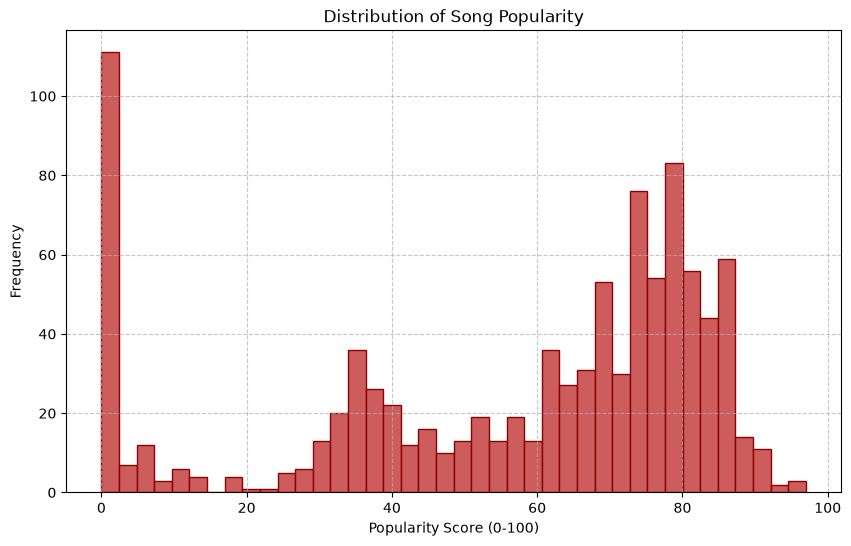

In [50]:
plt.figure(figsize=(10, 6))

plt.hist(
    df['popularity'],
    bins=40,
    color='indianred',
    edgecolor='darkred'
)

plt.title('Distribution of Song Popularity')
plt.xlabel('Popularity Score (0-100)')
plt.ylabel('Frequency')

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

C:\Users\Yllac\AppData\Local\Temp\ipykernel_6904\282407358.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


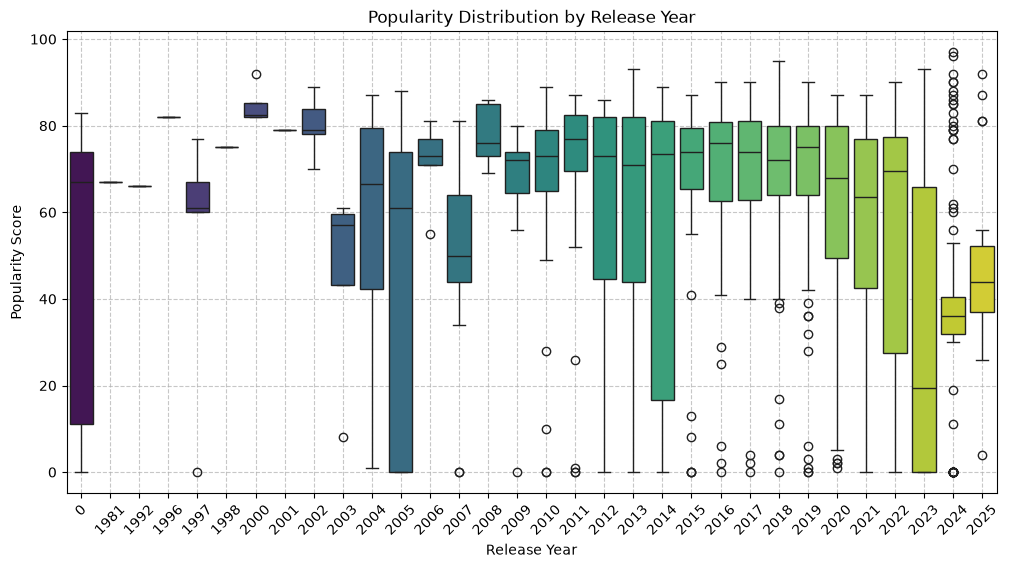

In [51]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    x='year',
    y='popularity',
    data=df,
    palette='viridis'
)

plt.title('Popularity Distribution by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Popularity Score')

plt.xticks(rotation=45)

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

In [52]:
if 'duration_min' not in df.columns and 'duration_ms' in df.columns:
    df['duration_min'] = df['duration_ms'] / 60000

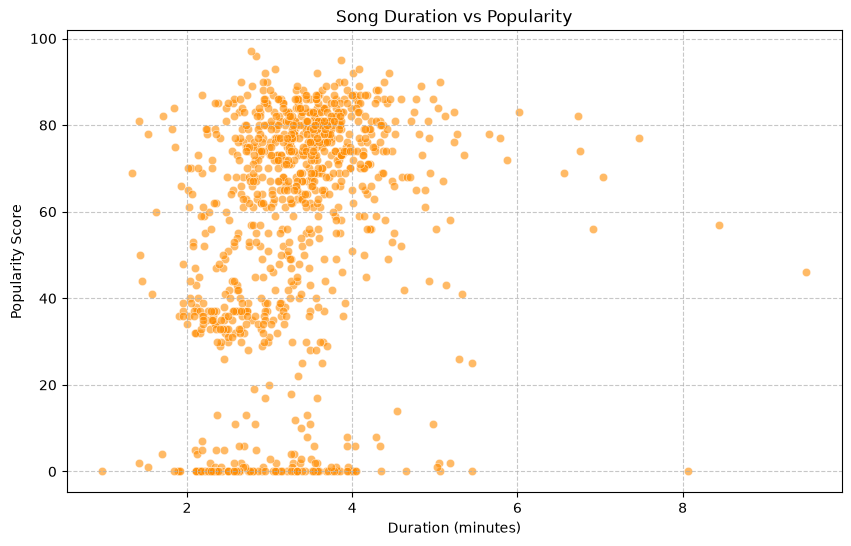

In [53]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='duration_min',
    y='popularity',
    data=df,
    alpha=0.6,
    color='darkorange'
)

plt.title('Song Duration vs Popularity')
plt.xlabel('Duration (minutes)')
plt.ylabel('Popularity Score')

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

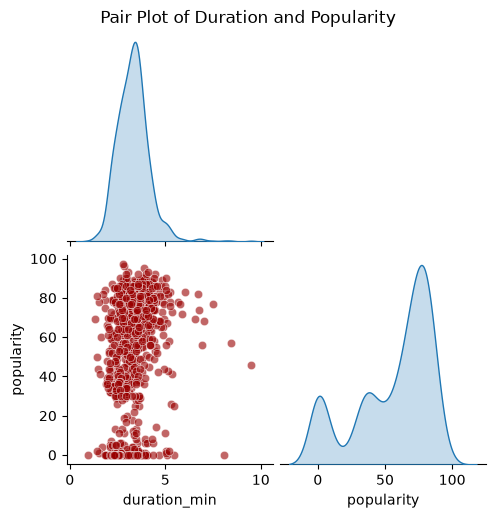

In [54]:
key_features = [
    'duration_min',
    'popularity'
]

sns.pairplot(
    df[key_features],
    diag_kind='kde',
    corner=True,
    plot_kws={
        'alpha': 0.6,
        'color': '#990000'
    }
)

plt.suptitle(
    'Pair Plot of Duration and Popularity',
    y=1.02
)

plt.show()

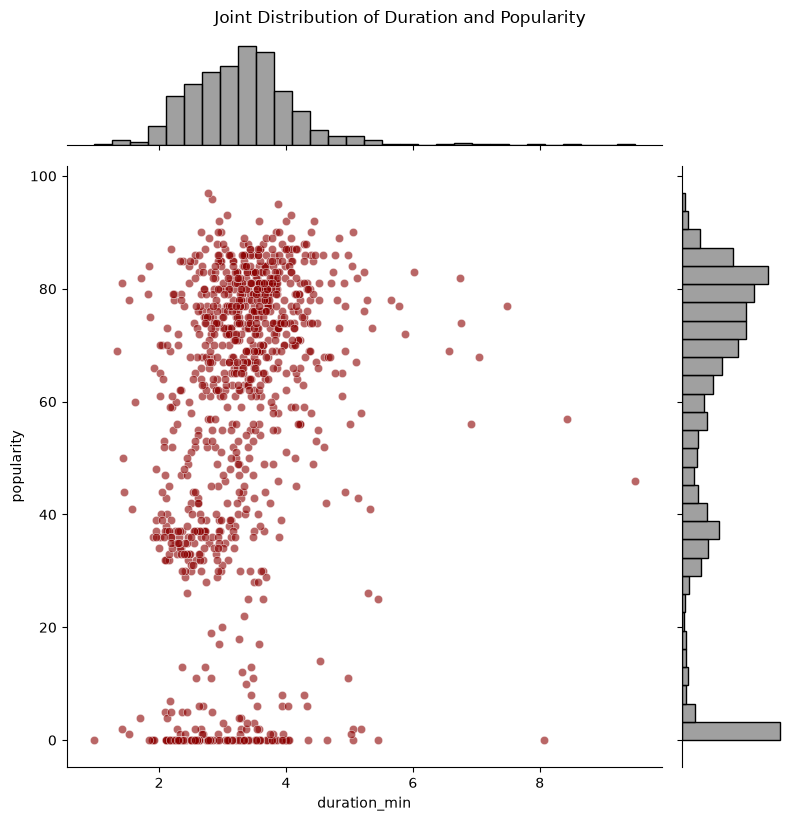

In [55]:
sns.jointplot(
    x='duration_min',
    y='popularity',
    data=df,
    kind='scatter',
    height=8,
    marginal_kws={
        'bins': 30,
        'color': 'gray',
        'edgecolor': 'black'
    },
    joint_kws={
        'alpha': 0.6,
        'color': 'darkred'
    }
)

plt.suptitle(
    'Joint Distribution of Duration and Popularity',
    y=1.02
)

plt.show()

In [56]:
import os
import webbrowser

from matplotlib.animation import FuncAnimation
from matplotlib.animation import PillowWriter

In [57]:
animation_df = pd.read_csv(
    "spotify_top_1000_tracks.csv"
)

animation_df['release_date'] = pd.to_datetime(
    animation_df['release_date'],
    errors='coerce'
)

animation_df['year'] = animation_df['release_date'].dt.year

animation_df = animation_df.dropna(
    subset=['year']
)

yearly_popularity = (
    animation_df
    .groupby('year')['popularity']
    .mean()
    .reset_index()
)

yearly_popularity = yearly_popularity.sort_values('year')

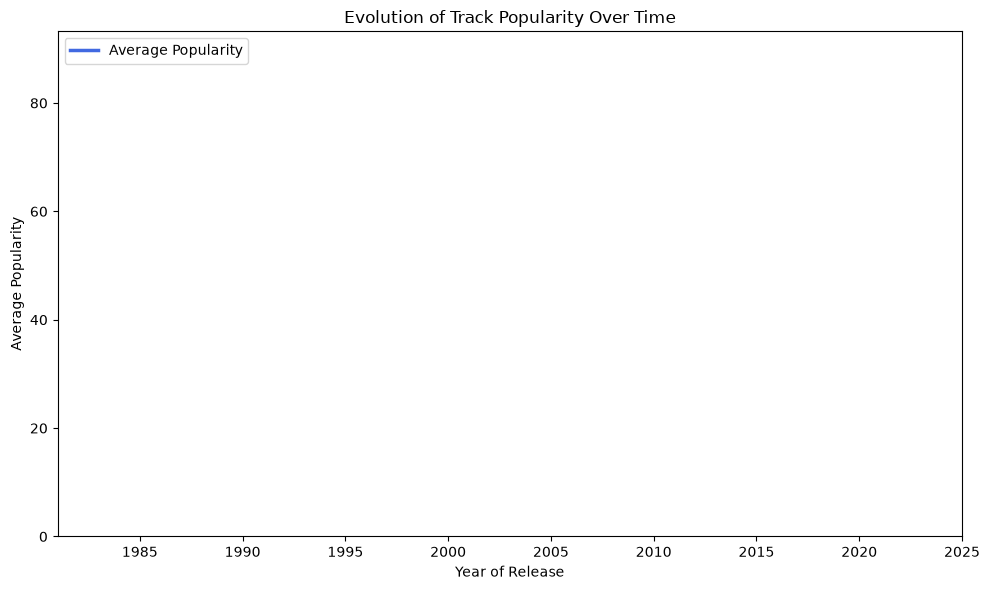

In [58]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.set_xlim(
    yearly_popularity['year'].min(),
    yearly_popularity['year'].max()
)

ax.set_ylim(
    0,
    yearly_popularity['popularity'].max() * 1.1
)

line, = ax.plot(
    [],
    [],
    color='royalblue',
    linewidth=2.5,
    label='Average Popularity'
)

ax.set_title(
    "Evolution of Track Popularity Over Time"
)

ax.set_xlabel("Year of Release")
ax.set_ylabel("Average Popularity")

ax.legend(loc="upper left")

plt.tight_layout()

In [59]:
def animate(i):

    x = yearly_popularity['year'][:i]
    y = yearly_popularity['popularity'][:i]

    line.set_data(x, y)

    return line,

In [60]:
ani = FuncAnimation(
    fig,
    animate,
    frames=len(yearly_popularity),
    interval=100,
    repeat=False
)

gif_path = os.path.abspath(
    "yearly_popularity_trend.gif"
)

ani.save(
    gif_path,
    writer=PillowWriter(fps=10)
)

print("GIF Saved:", gif_path)

webbrowser.open(f"file://{gif_path}")

plt.close(fig)

GIF Saved: c:\Users\Yllac\Downloads\Lab8_Data_Visualization\Lab8_Data_Visualization_Fabia\yearly_popularity_trend.gif


In [61]:
dataset_path = "spotify_top_1000_tracks.csv"

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

student_name = "Your Name"
student_id = "202512345"

id_num = int(student_id[-3:])

color1 = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5) % 256:02x}"
color2 = f"#{(id_num * 2) % 256:02x}{(id_num * 9) % 256:02x}{(id_num * 4) % 256:02x}"

# Create duration_min if needed
if 'duration_min' not in df.columns and 'duration_ms' in df.columns:
    df['duration_min'] = df['duration_ms'] / 60000

# Rebuild release_year safely
if 'year' in df.columns:
    df['release_year'] = df['year']

df['decade'] = (df['release_year'] // 10) * 10

print("Setup Complete")

Setup Complete


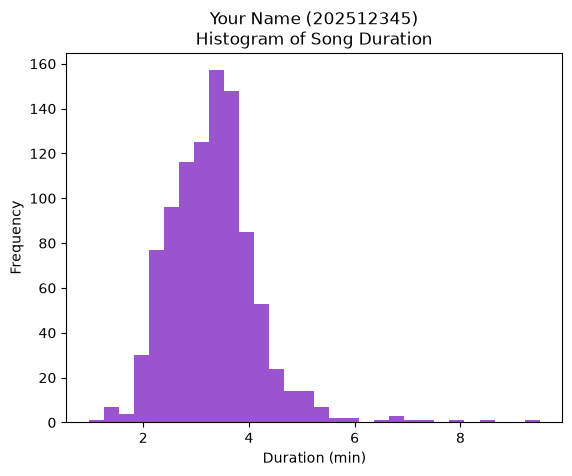

In [63]:
df['duration_min'].plot(
    kind='hist',
    bins=30,
    color=color1,
    alpha=0.7
)

plt.title(f"{student_name} ({student_id})\nHistogram of Song Duration")
plt.xlabel("Duration (min)")
plt.ylabel("Frequency")
plt.show()

C:\Users\Yllac\AppData\Local\Temp\ipykernel_6904\444031162.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


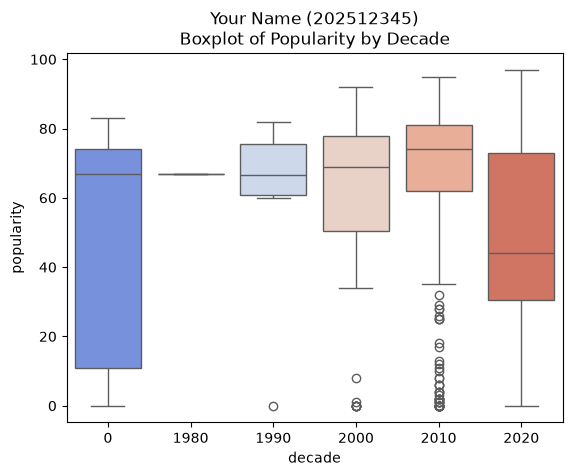

In [64]:
sns.boxplot(
    x='decade',
    y='popularity',
    data=df,
    palette='coolwarm'
)

plt.title(f"{student_name} ({student_id})\nBoxplot of Popularity by Decade")
plt.show()

C:\Users\Yllac\AppData\Local\Temp\ipykernel_6904\4099255378.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


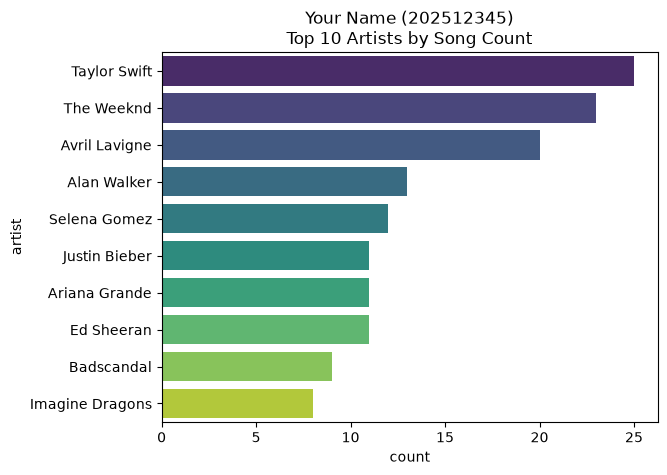

In [65]:
sns.countplot(
    y='artist',
    data=df,
    order=df['artist'].value_counts().head(10).index,
    palette='viridis'
)

plt.title(f"{student_name} ({student_id})\nTop 10 Artists by Song Count")
plt.show()

C:\Users\Yllac\AppData\Local\Temp\ipykernel_6904\3455323646.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


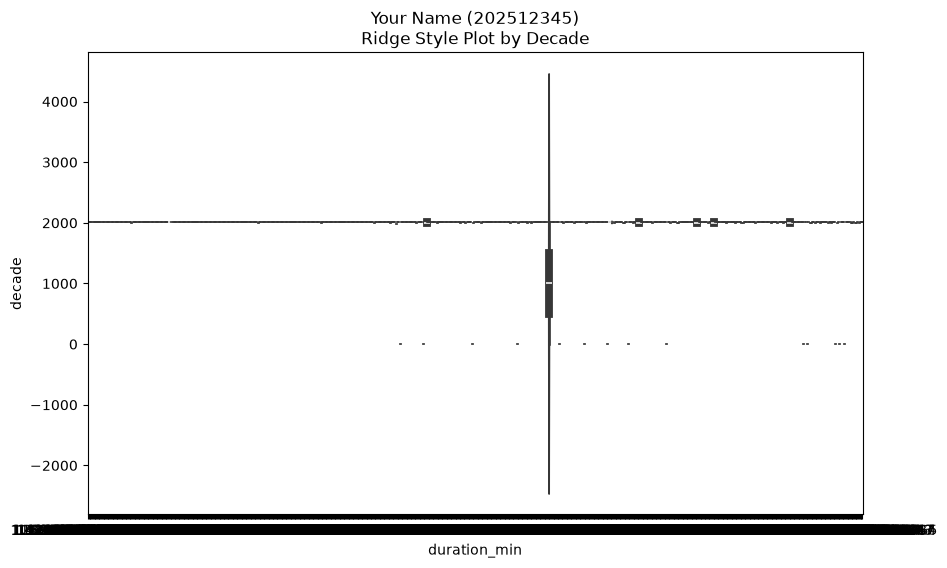

In [66]:
plt.figure(figsize=(10,6))

sns.violinplot(
    data=df,
    x='duration_min',
    y='decade',
    palette='coolwarm'
)

plt.title(f"{student_name} ({student_id})\nRidge Style Plot by Decade")
plt.show()

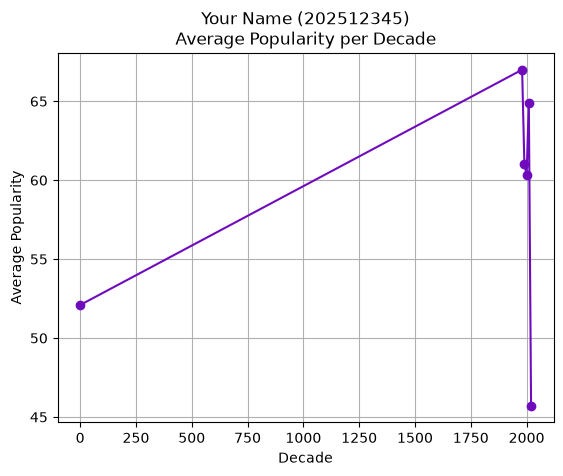

In [67]:
avg_pop = df.groupby('decade')['popularity'].mean()

avg_pop.plot(
    kind='line',
    color=color1,
    marker='o'
)

plt.title(f"{student_name} ({student_id})\nAverage Popularity per Decade")
plt.xlabel("Decade")
plt.ylabel("Average Popularity")
plt.grid(True)

plt.show()

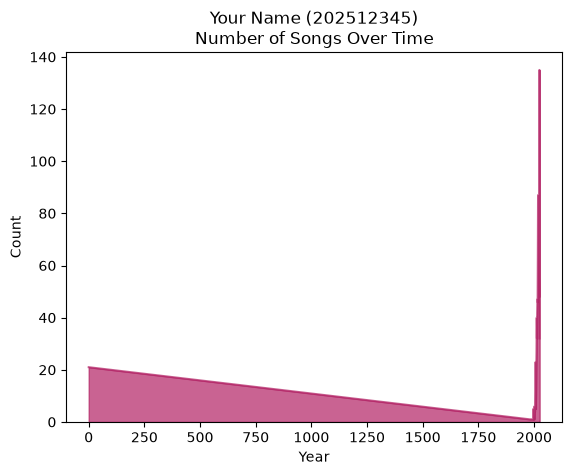

In [68]:
count_by_year = df['release_year'].value_counts().sort_index()

count_by_year.plot(
    kind='area',
    color=color2,
    alpha=0.7
)

plt.title(f"{student_name} ({student_id})\nNumber of Songs Over Time")
plt.xlabel("Year")
plt.ylabel("Count")

plt.show()

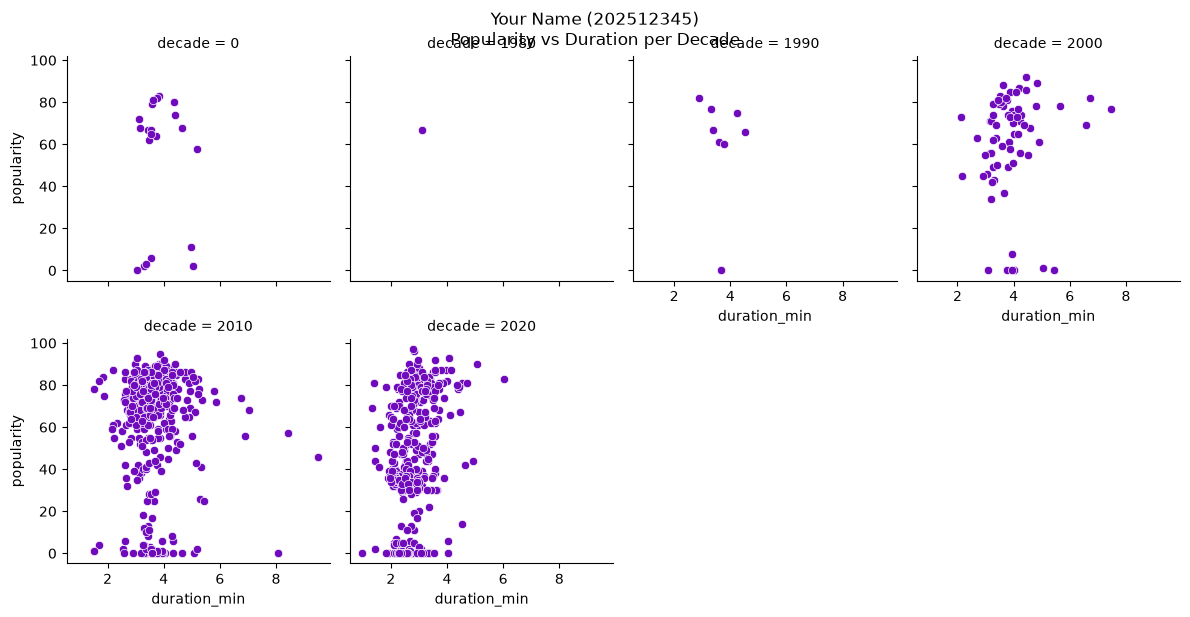

In [69]:
g = sns.FacetGrid(
    df,
    col='decade',
    col_wrap=4,
    height=3
)

g.map_dataframe(
    sns.scatterplot,
    x='duration_min',
    y='popularity',
    color=color1
)

g.fig.suptitle(
    f"{student_name} ({student_id})\nPopularity vs Duration per Decade",
    y=1.02
)

plt.show()

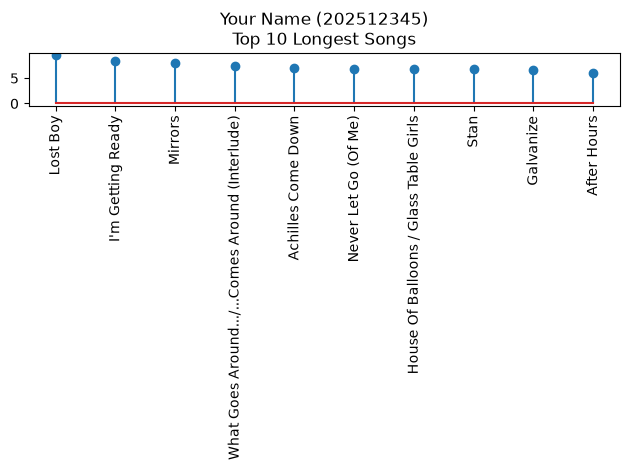

In [70]:
longest = df.nlargest(10, 'duration_min')

plt.stem(
    longest['track_name'],
    longest['duration_min']
)

plt.xticks(rotation=90)

plt.title(f"{student_name} ({student_id})\nTop 10 Longest Songs")

plt.tight_layout()

plt.show()

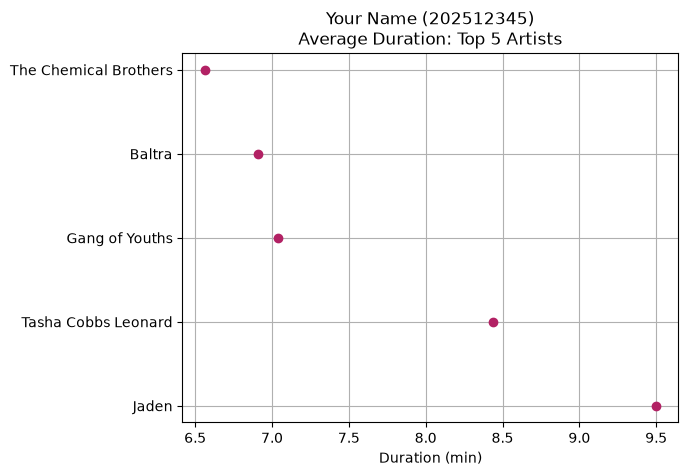

In [71]:
avg_duration = (
    df.groupby('artist')['duration_min']
    .mean()
    .nlargest(5)
)

plt.plot(
    avg_duration.values,
    avg_duration.index,
    'o',
    color=color2
)

plt.title(f"{student_name} ({student_id})\nAverage Duration: Top 5 Artists")

plt.xlabel("Duration (min)")
plt.grid(True)

plt.show()

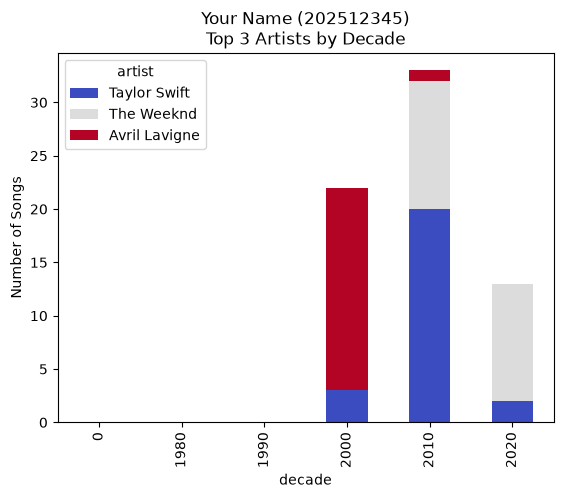

In [72]:
top3 = df['artist'].value_counts().head(3).index

crosstab = pd.crosstab(
    df['decade'],
    df['artist']
)

crosstab[top3].plot(
    kind='bar',
    stacked=True,
    colormap='coolwarm'
)

plt.title(f"{student_name} ({student_id})\nTop 3 Artists by Decade")
plt.ylabel("Number of Songs")

plt.show()

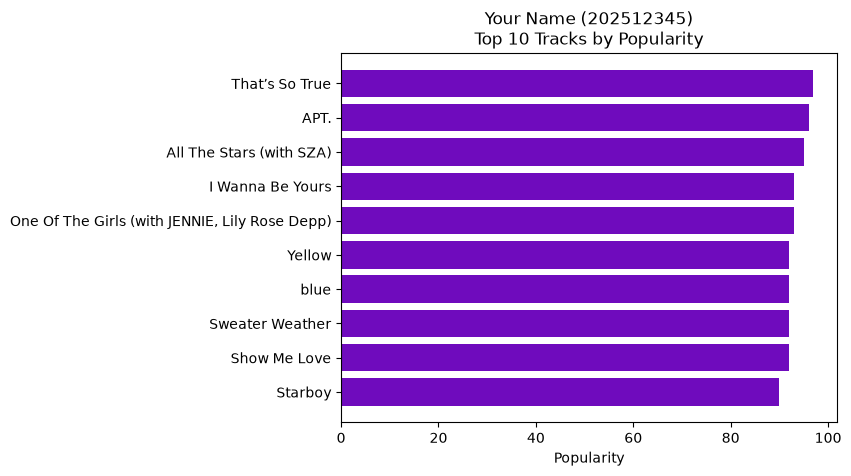

In [73]:
top_tracks = df.nlargest(10, 'popularity')

plt.barh(
    top_tracks['track_name'],
    top_tracks['popularity'],
    color=color1
)

plt.xlabel("Popularity")

plt.title(
    f"{student_name} ({student_id})\nTop 10 Tracks by Popularity"
)

plt.gca().invert_yaxis()

plt.show()

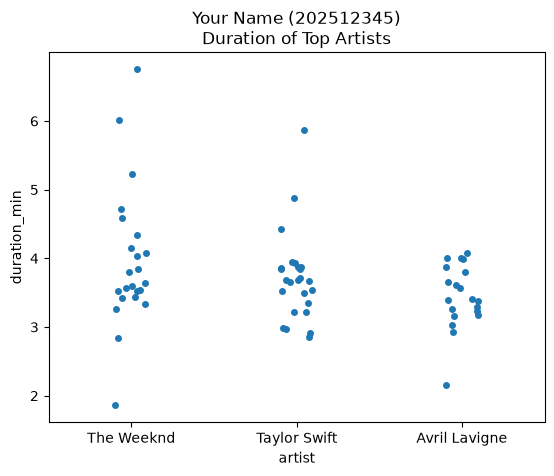

In [74]:
top_artists = df['artist'].value_counts().head(3).index

sns.stripplot(
    data=df[df['artist'].isin(top_artists)],
    x='artist',
    y='duration_min'
)

plt.title(
    f"{student_name} ({student_id})\nDuration of Top Artists"
)

plt.show()

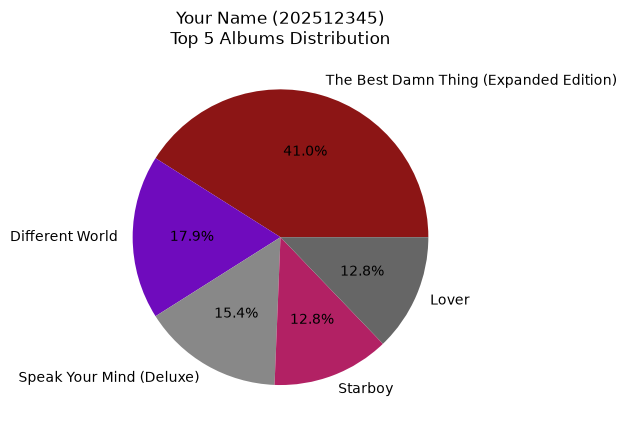

In [75]:
top_albums = df['album'].value_counts().head(5)

colors = [
    '#8C1515',
    color1,
    '#888888',
    color2,
    '#666666'
]

plt.pie(
    top_albums,
    labels=top_albums.index,
    autopct='%1.1f%%',
    colors=colors
)

plt.title(
    f"{student_name} ({student_id})\nTop 5 Albums Distribution"
)

plt.show()

In [76]:
print(df.columns)

Index(['track_name', 'artist', 'album', 'popularity', 'duration_min', 'year',
       'release_year', 'decade'],
      dtype='str')


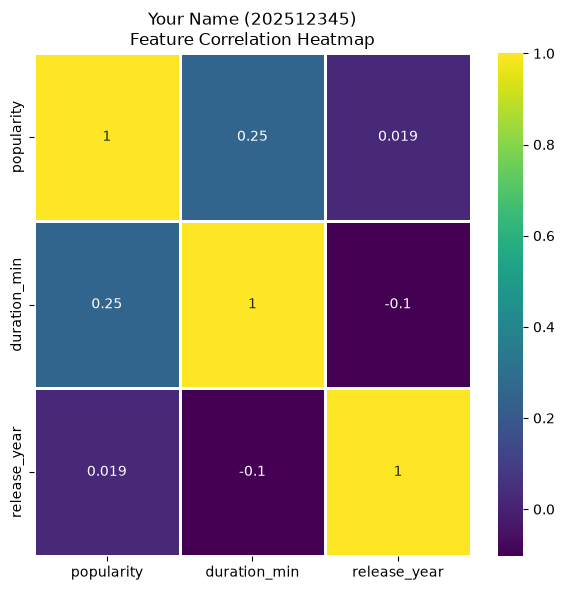

In [77]:
numerical_cols = [
    'popularity',
    'duration_min',
    'release_year'
]

df_numeric = df[numerical_cols].dropna()

corr_matrix = df_numeric.corr()

plt.figure(figsize=(6, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='viridis',
    linewidths=0.75
)

plt.title(
    f"{student_name} ({student_id})\nFeature Correlation Heatmap"
)

plt.tight_layout()
plt.show()

In [78]:
print(df[['duration_min','popularity','release_year']].isnull().sum())

duration_min    0
popularity      0
release_year    0
dtype: int64


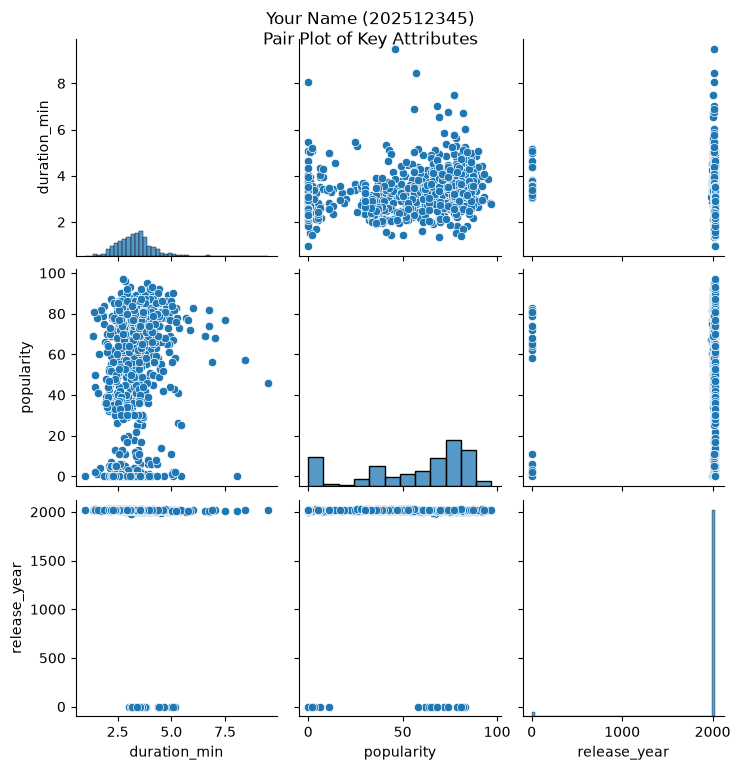

In [79]:
sns.pairplot(
    df[
        [
            'duration_min',
            'popularity',
            'release_year'
        ]
    ].dropna(),
    diag_kind='hist'
)

plt.suptitle(
    f"{student_name} ({student_id})\nPair Plot of Key Attributes",
    y=1.02
)

plt.show()

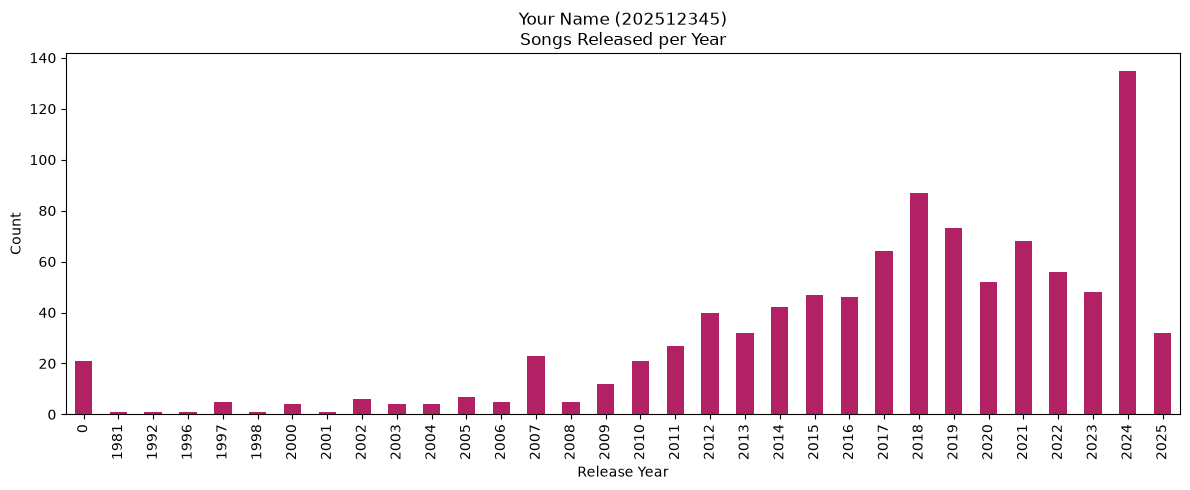

In [80]:
df['release_year'].value_counts().sort_index().plot(
    kind='bar',
    color=color2,
    figsize=(12,5)
)

plt.title(
    f"{student_name} ({student_id})\nSongs Released per Year"
)

plt.xlabel("Release Year")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

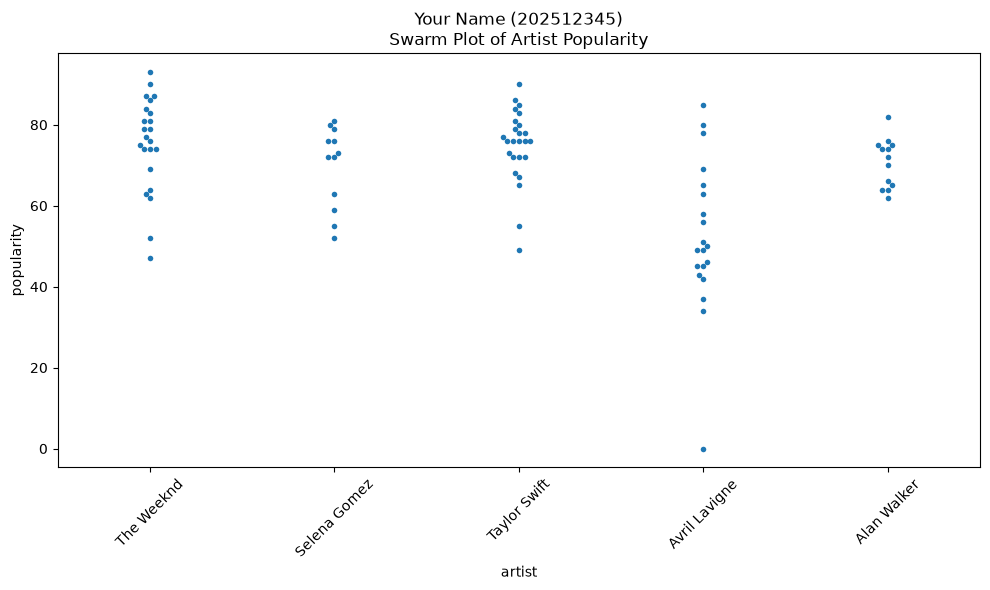

In [81]:
top_artists = df['artist'].value_counts().head(5).index

sample_df = df[df['artist'].isin(top_artists)]

plt.figure(figsize=(10,6))

sns.swarmplot(
    data=sample_df,
    x='artist',
    y='popularity',
    size=4
)

plt.xticks(rotation=45)

plt.title(
    f"{student_name} ({student_id})\nSwarm Plot of Artist Popularity"
)

plt.tight_layout()
plt.show()

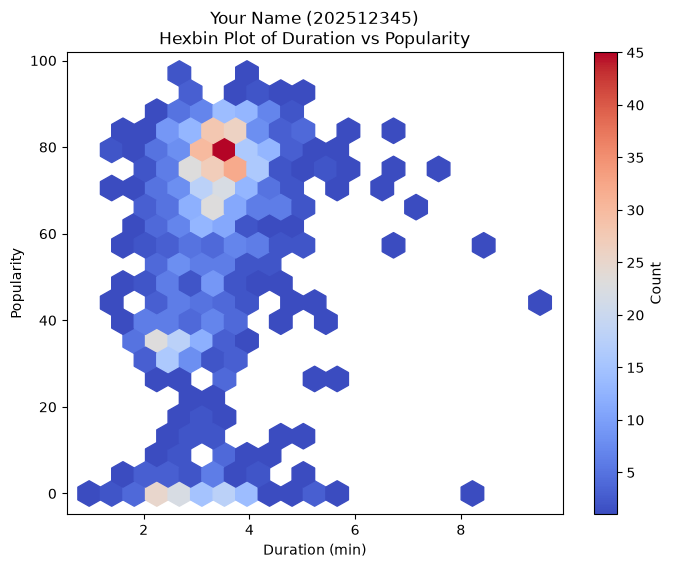

In [82]:
plt.figure(figsize=(8,6))

plt.hexbin(
    df['duration_min'],
    df['popularity'],
    gridsize=20,
    cmap='coolwarm',
    mincnt=1
)

plt.colorbar(label="Count")

plt.xlabel("Duration (min)")
plt.ylabel("Popularity")

plt.title(
    f"{student_name} ({student_id})\nHexbin Plot of Duration vs Popularity"
)

plt.show()

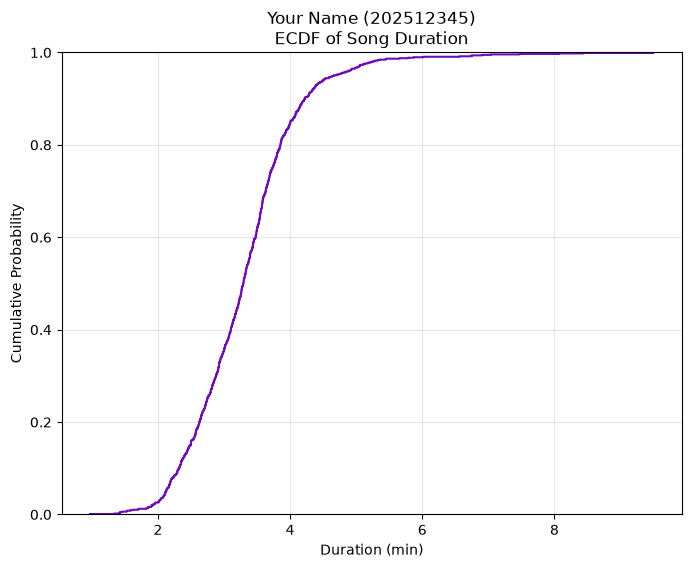

In [83]:
plt.figure(figsize=(8,6))

sns.ecdfplot(
    data=df,
    x='duration_min',
    color=color1
)

plt.title(
    f"{student_name} ({student_id})\nECDF of Song Duration"
)

plt.xlabel("Duration (min)")
plt.ylabel("Cumulative Probability")

plt.grid(True, alpha=0.3)

plt.show()

In [84]:
top3 = df['artist'].value_counts().head(3).index

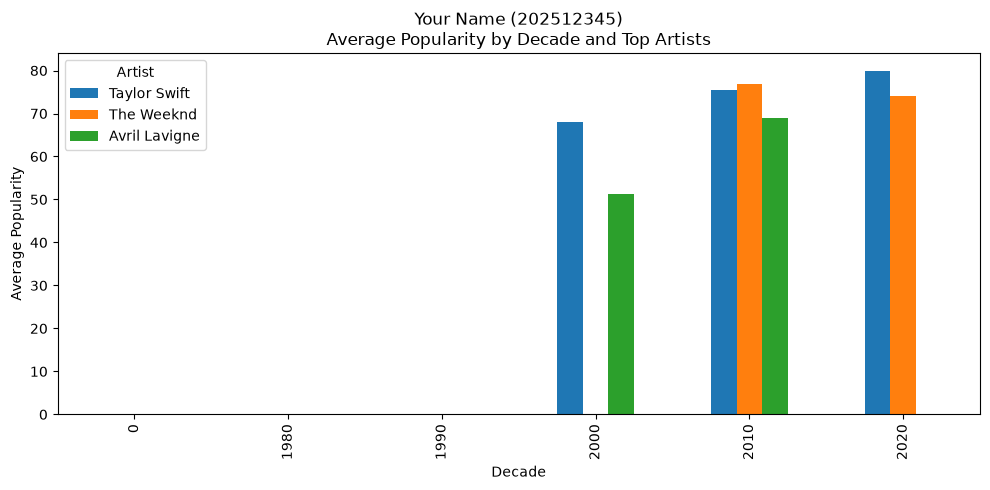

In [85]:
avg_artist_decade = (
    df.groupby(
        ['decade', 'artist']
    )['popularity']
    .mean()
    .unstack()
    .fillna(0)
)

avg_artist_decade[top3].plot(
    kind='bar',
    figsize=(10,5)
)

plt.title(
    f"{student_name} ({student_id})\nAverage Popularity by Decade and Top Artists"
)

plt.xlabel("Decade")
plt.ylabel("Average Popularity")

plt.legend(title="Artist")

plt.tight_layout()
plt.show()